<div align="center">
<h1 > Riyadh Cardiorespiratory Hospital Admissions Dataset (2020–2024) </h1>
<img src="MOH-1.png" alt="Dataset Preview" width="600">
</div>

## 1 ) Data Understanding : 

| Column Name | Description |
| :--- | :--- |
| **admission_date** |The precise date and time of hospital admission (YYYY-MM-DD HH:mm:ss). |
| **hospital_name** | Name of the hospital where the admission occurred (e.g., Riyadh General Hospital). |
| **admission_count** | The number of admissions during the specified hour. |
| **condition_type** | Type of cardiorespiratory condition (e.g., Asthma, COPD, Heart Attack, Other Respiratory Issues).|
| **patient_age_group** | The age group of admitted patients (e.g., 0–17, 18–45, 46–65, 66+). |
| **patient_gender** | Gender of the patients (Male/Female). |
| **readmission_count** |  Count of patients readmitted within 30 days. |
| **severity_level** | Severity level of the condition upon admission (Mild, Moderate, Severe). |
| **length_of_stay_avg** | Average length of stay (in days) for admitted patients.|
| **seasonal_indicator** | Seasonal classification for the date of admission (Winter, Spring, Summer, Fall).|
| **comorbid_conditions_count** | Number of additional health conditions affecting admitted patients. |
| **primary_diagnosis_code** |Diagnostic code for the primary condition (e.g., J45, J44, I21). |
| **daily_medication_dosage** | Total daily dosage of medications prescribed for cardiorespiratory conditions (mg). |
| **emergency_visit_count** | The number of emergency visits for cardiorespiratory issues during the hour. |


## 2) Data Exploration 

In [2]:
import numpy as np 
import pandas as pd 
import plotly.express as px 
import streamlit as st

In [3]:
df =pd.read_csv(r"C:\Users\Latif\Desktop\Epsilon Data Analysis With Python Project\Hospital_Dataset_2020_2024.csv")
df

,admission_date,hospital_name,admission_count,condition_type,patient_age_group,patient_gender,readmission_count,severity_level,length_of_stay_avg,seasonal_indicator,comorbid_conditions_count,primary_diagnosis_code,daily_medication_dosage,emergency_visit_count
0,2020-01-01 00:00:00,Mecca City Hospital,1,Asthma,46-65,Female,0,Moderate,2.781828,Winter,1,Other,17.455517,2
1,2020-01-01 01:00:00,Dammam General Hospital,2,Asthma,0-17,Female,1,Mild,4.141432,Winter,0,Other,15.099498,3
2,2020-01-01 02:00:00,Mecca City Hospital,1,Asthma,46-65,Female,1,Moderate,8.507026,Winter,2,I21,23.087843,3
3,2020-01-01 03:00:00,Medina Specialist Hospital,3,Asthma,46-65,Male,0,Mild,4.622657,Winter,3,J45,25.247579,2
4,2020-01-01 04:00:00,Medina Specialist Hospital,5,COPD,18-45,Female,2,Moderate,5.818385,Winter,3,J45,18.255290,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41539,2024-09-26 19:00:00,King Saud Hospital,4,Asthma,46-65,Male,1,Moderate,6.560851,Fall,1,Other,19.060730,1
41540,2024-09-26 20:00:00,Dammam General Hospital,3,COPD,0-17,Male,0,Mild,4.453949,Fall,2,Other,17.128869,1
41541,2024-09-26 21:00:00,Riyadh National Hospital,2,Asthma,46-65,Male,0,Moderate,4.248567,Fall,1,J45,15.250912,1
41542,2024-09-26 22:00:00,King Saud Hospital,0,Asthma,18-45,Male,0,Mild,4.666558,Fall,3,J44,23.296328,0


## 2.1 Cleaning Steps 
#### 2.1.1 Checking Data Types 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41544 entries, 0 to 41543
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   admission_date             41544 non-null  object 
 1   hospital_name              41544 non-null  object 
 2   admission_count            41544 non-null  int64  
 3   condition_type             41544 non-null  object 
 4   patient_age_group          41544 non-null  object 
 5   patient_gender             41544 non-null  object 
 6   readmission_count          41544 non-null  int64  
 7   severity_level             41544 non-null  object 
 8   length_of_stay_avg         41544 non-null  float64
 9   seasonal_indicator         41544 non-null  object 
 10  comorbid_conditions_count  41544 non-null  int64  
 11  primary_diagnosis_code     41544 non-null  object 
 12  daily_medication_dosage    41544 non-null  float64
 13  emergency_visit_count      41544 non-null  int

In [5]:
df['admission_date']=pd.to_datetime(df['admission_date'])
df['admission_date']

0       2020-01-01 00:00:00
1       2020-01-01 01:00:00
2       2020-01-01 02:00:00
3       2020-01-01 03:00:00
4       2020-01-01 04:00:00
                ...        
41539   2024-09-26 19:00:00
41540   2024-09-26 20:00:00
41541   2024-09-26 21:00:00
41542   2024-09-26 22:00:00
41543   2024-09-26 23:00:00
Name: admission_date, Length: 41544, dtype: datetime64[ns]

#### 2.1.2 Checking Missing Values 

In [6]:
df.isna().sum()

admission_date               0
hospital_name                0
admission_count              0
condition_type               0
patient_age_group            0
patient_gender               0
readmission_count            0
severity_level               0
length_of_stay_avg           0
seasonal_indicator           0
comorbid_conditions_count    0
primary_diagnosis_code       0
daily_medication_dosage      0
emergency_visit_count        0
dtype: int64

In [7]:
df['daily_medication_dosage']=df['daily_medication_dosage'].round(2)
df['daily_medication_dosage']

0        17.46
1        15.10
2        23.09
3        25.25
4        18.26
         ...  
41539    19.06
41540    17.13
41541    15.25
41542    23.30
41543    21.35
Name: daily_medication_dosage, Length: 41544, dtype: float64

#### 2.1.3 Checking Duplicates 

In [8]:
df.duplicated().sum()

np.int64(0)

#### 2.1.4 Checking Outliers 

In [9]:
for col in df.select_dtypes(include='number').columns:
    fig=px.box(df, x= col , color_discrete_sequence=['#49A684'])
    fig.show()

#### 2.1.5 Checking Inconsistent Values

In [10]:
df.describe(include='object')

,hospital_name,condition_type,patient_age_group,patient_gender,severity_level,seasonal_indicator,primary_diagnosis_code
count,41544,41544,41544,41544,41544,41544,41544
unique,8,4,4,2,3,4,4
top,Riyadh National Hospital,Asthma,18-45,Male,Moderate,Spring,J45
freq,5378,20752,16708,24938,16636,11040,16759


In [11]:
df.describe().round(2)

,admission_date,admission_count,readmission_count,length_of_stay_avg,comorbid_conditions_count,daily_medication_dosage,emergency_visit_count
count,41544,41544.00,41544.00,41544.00,41544.00,41544.00,41544.00
mean,2022-05-15 11:30:00,2.00,0.50,4.99,2.00,20.02,1.01
min,2020-01-01 00:00:00,0.00,0.00,1.00,0.00,5.00,0.00
25%,2021-03-08 17:45:00,1.00,0.00,3.96,1.00,16.65,0.00
50%,2022-05-15 11:30:00,2.00,0.00,4.99,2.00,20.03,1.00
75%,2023-07-22 05:15:00,3.00,1.00,6.01,3.00,23.41,2.00
max,2024-09-26 23:00:00,10.00,5.00,10.00,11.00,40.00,7.00
std,NaN,1.42,0.71,1.50,1.42,4.98,1.00


In [12]:
cat_cols=df.select_dtypes(include='object').columns
cat_cols

Index(['hospital_name', 'condition_type', 'patient_age_group',
       'patient_gender', 'severity_level', 'seasonal_indicator',
       'primary_diagnosis_code'],
      dtype='object')

In [13]:
for col in cat_cols:
    print(col)
    print(df[col].nunique())
    print(df[col].unique())
    print('*'*100)

hospital_name
8
['Mecca City Hospital' 'Dammam General Hospital'
 'Medina Specialist Hospital' 'Dammam Central Hospital'
 'King Saud Hospital' 'Jeddah National Hospital'
 'Riyadh National Hospital' 'Riyadh General Hospital']
****************************************************************************************************
condition_type
4
['Asthma' 'COPD' 'Heart Attack' 'Other Respiratory Issues']
****************************************************************************************************
patient_age_group
4
['46-65' '0-17' '18-45' '66+']
****************************************************************************************************
patient_gender
2
['Female' 'Male']
****************************************************************************************************
severity_level
3
['Moderate' 'Mild' 'Severe']
****************************************************************************************************
seasonal_indicator
4
['Winter' 'Spring' 'Summer' 'Fall']
****

## 3.Data Analysis

In [14]:
df.head()

,admission_date,hospital_name,admission_count,condition_type,patient_age_group,patient_gender,readmission_count,severity_level,length_of_stay_avg,seasonal_indicator,comorbid_conditions_count,primary_diagnosis_code,daily_medication_dosage,emergency_visit_count
0,2020-01-01 00:00:00,Mecca City Hospital,1,Asthma,46-65,Female,0,Moderate,2.781828,Winter,1,Other,17.46,2
1,2020-01-01 01:00:00,Dammam General Hospital,2,Asthma,0-17,Female,1,Mild,4.141432,Winter,0,Other,15.10,3
2,2020-01-01 02:00:00,Mecca City Hospital,1,Asthma,46-65,Female,1,Moderate,8.507026,Winter,2,I21,23.09,3
3,2020-01-01 03:00:00,Medina Specialist Hospital,3,Asthma,46-65,Male,0,Mild,4.622657,Winter,3,J45,25.25,2
4,2020-01-01 04:00:00,Medina Specialist Hospital,5,COPD,18-45,Female,2,Moderate,5.818385,Winter,3,J45,18.26,1


## 3.1 Univariate Analysis

In [15]:
for col in df.columns:
    fig= px.histogram(df,x= col,color_discrete_sequence=['#A69563'],text_auto= True )
    fig.show()

## 3.2 1. Temporal & Seasonal Trend Analysis

### How have total admission counts and emergency visits evolved year-over-year from 2020 through September 2024?

In [16]:
df['Year']=df['admission_date'].dt.year
df['Year']

0        2020
1        2020
2        2020
3        2020
4        2020
         ... 
41539    2024
41540    2024
41541    2024
41542    2024
41543    2024
Name: Year, Length: 41544, dtype: int32

In [52]:
yearly_trend=df.groupby('Year')[['admission_count','emergency_visit_count']].sum().reset_index()
yearly_trend

,Year,admission_count,emergency_visit_count
0,2020,17736,8823
1,2021,17425,8851
2,2022,17592,8901
3,2023,17442,8731
4,2024,12933,6478


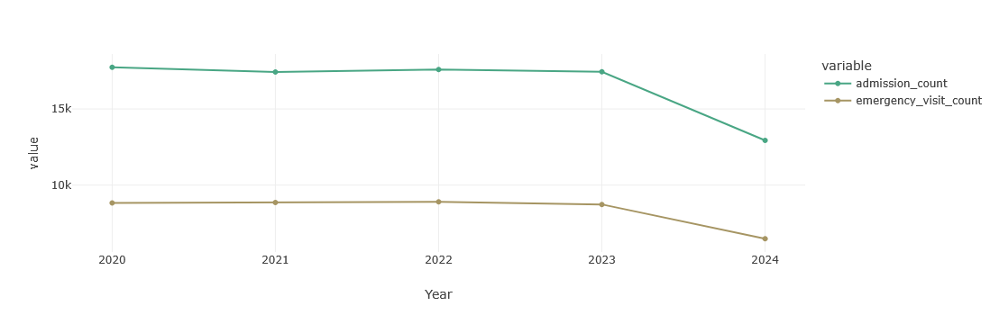

In [53]:
fig_pattern=px.line(yearly_trend, x='Year', y=['admission_count','emergency_visit_count'], color_discrete_sequence=['#49A684','#A69563'],markers=True)
fig_pattern.update_layout(xaxis=dict(tickmode='linear', dtick=1))
fig_pattern.show()

In [50]:
df['Month'] = df['admission_date'].dt.month_name()
monthly_pattern = df.groupby('Month')['admission_count'].mean().reset_index().round(2)
monthly_pattern 

,Month,admission_count
0,April,1.94
1,August,2.00
2,December,2.03
3,February,2.00
4,January,1.96
5,July,1.99
6,June,2.03
7,March,2.01
8,May,2.02
9,November,2.01


In [19]:
fig = px.line( monthly_pattern, x='Month', y='admission_count', title='(Admission Monthly Pattern)',color_discrete_sequence=['#A69563'],labels={ 'admission_count': 'Average admission per month'},markers=True).update_xaxes(tickmode='linear', tick0=1, dtick=1)
fig.show()

In [20]:
df['Hour'] = df['admission_date'].dt.hour
Hour_pattern = df.groupby('Hour')['admission_count'].mean().reset_index().round(2)
Hour_pattern 

,Hour,admission_count
0,0,2.04
1,1,1.95
2,2,1.99
3,3,2.03
4,4,2.00
5,5,1.98
6,6,1.96
7,7,2.03
8,8,2.01
9,9,2.01


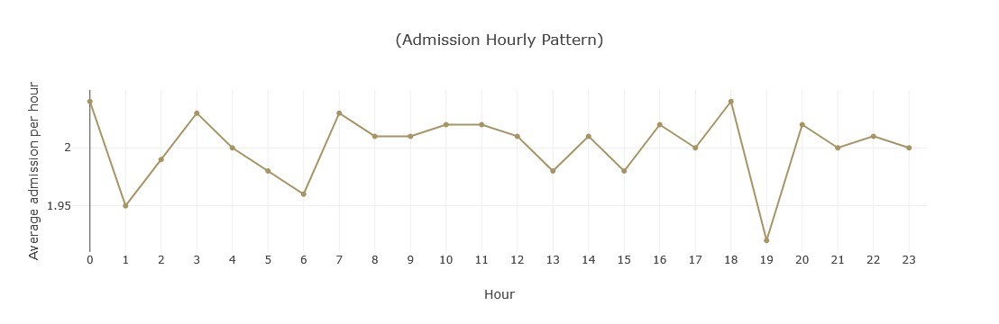

In [54]:
fig_2 = px.line(Hour_pattern , x='Hour', y='admission_count', title='(Admission Hourly Pattern)',color_discrete_sequence=['#A69563'],labels={ 'admission_count': 'Average admission per hour'},markers=True,).update_xaxes(range=[-0.5,23.5],tickmode='linear', tick0=1, dtick=1)
fig_2.show()

### ** Investigating correlations between environmental factors and hospitalizations for respiratory and cardiovascular conditions

In [22]:
months_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]

In [23]:
monthly_seasonal_df = df.groupby(['Month','seasonal_indicator','condition_type'])['admission_count'].mean().reset_index().round(2)
monthly_seasonal_df["Month"] = pd.Categorical( monthly_seasonal_df["Month"], categories=months_order, ordered=True)
monthly_seasonal_df = monthly_seasonal_df.sort_values("Month")
monthly_seasonal_df

,Month,seasonal_indicator,condition_type,admission_count
19,January,Winter,Other Respiratory Issues,1.97
18,January,Winter,Heart Attack,1.76
17,January,Winter,COPD,2.04
16,January,Winter,Asthma,1.97
15,February,Winter,Other Respiratory Issues,2.07
14,February,Winter,Heart Attack,2.03
13,February,Winter,COPD,2.00
12,February,Winter,Asthma,1.97
28,March,Spring,Asthma,2.04
31,March,Spring,Other Respiratory Issues,1.96


In [24]:
fig_env = px.line( monthly_seasonal_df, x='Month', y='admission_count', color='condition_type',facet_row='seasonal_indicator', title='Respiratory & Cardiovascular Admissions Across Seasons',template='plotly_white',height=1100)
fig_env.update_xaxes(matches=None)
fig_env.update_yaxes(matches=None)
fig_env.show()

### Analysis of Facility & Operational Performance of each hospital

In [25]:
dis_fig=px.pie(df,names='hospital_name',title='Distribution of Admission over Hospitals',template='plotly_white')
dis_fig.show()

In [56]:
hospital_summary = (df.groupby('hospital_name').agg({'admission_count': 'sum','length_of_stay_avg': 'mean','emergency_visit_count': 'sum',}).reset_index().round(2))
hospital_summary

,hospital_name,admission_count,length_of_stay_avg,emergency_visit_count
0,Dammam Central Hospital,10495,4.99,5316
1,Dammam General Hospital,10177,4.98,5172
2,Jeddah National Hospital,10500,5.01,5174
3,King Saud Hospital,10310,4.98,5054
4,Mecca City Hospital,10314,4.98,5227
5,Medina Specialist Hospital,10394,5.00,5271
6,Riyadh General Hospital,10200,5.01,5196
7,Riyadh National Hospital,10738,5.00,5374


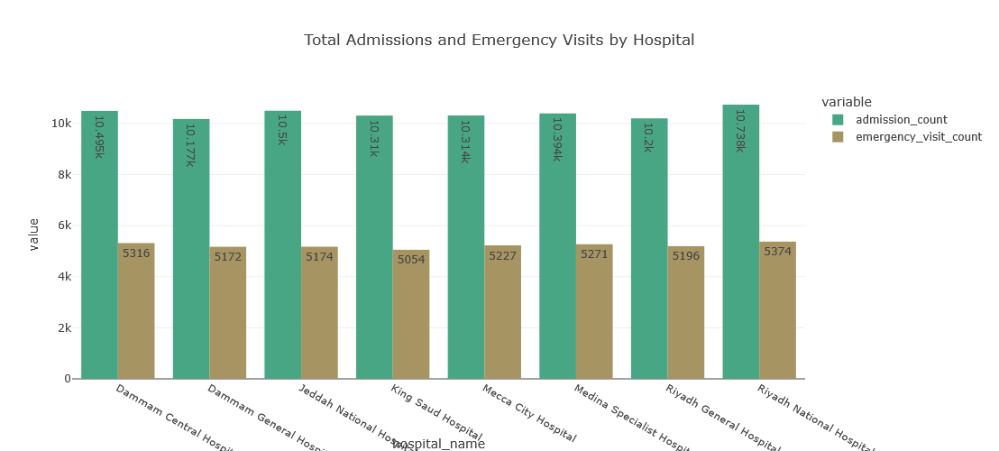

In [67]:
fig_hosp = px.bar(hospital_summary,x='hospital_name',y=['admission_count', 'emergency_visit_count'],barmode='group',color_discrete_sequence=['#49A684','#A69563'],title='Total Admissions and Emergency Visits by Hospital',text_auto=True,height=500)
fig_hosp

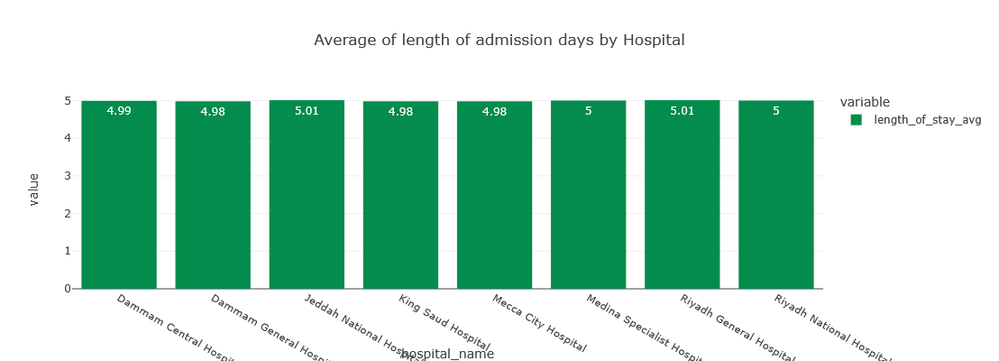

In [68]:
fig_hosp_len = px.bar(hospital_summary,x='hospital_name',y=['length_of_stay_avg'],barmode='group',color_discrete_sequence=['#038C4C'],title='Average of length of admission days by Hospital',text_auto=True,height=400)
fig_hosp_len

### Analysis of Patient Demographics & Epidemiological Insights

In [26]:
age_df=df.groupby(['patient_age_group','condition_type','patient_gender'])['admission_count'].sum().reset_index()
age_df

,patient_age_group,condition_type,patient_gender,admission_count
0,0-17,Asthma,Female,3423
1,0-17,Asthma,Male,4961
2,0-17,COPD,Female,1362
3,0-17,COPD,Male,2106
4,0-17,Heart Attack,Female,684
5,0-17,Heart Attack,Male,978
6,0-17,Other Respiratory Issues,Female,1389
7,0-17,Other Respiratory Issues,Male,1914
8,18-45,Asthma,Female,6721
9,18-45,Asthma,Male,10065


In [27]:
age_con_fig = px.bar(age_df,x='patient_age_group',y='admission_count',color='condition_type',barmode='group',facet_row='patient_gender',template='plotly_white',height=1000)
age_con_fig.show()


In [28]:
severe_df=df.groupby(['condition_type','severity_level','patient_age_group','patient_gender'])['admission_count'].sum().reset_index()
severe_df

,condition_type,severity_level,patient_age_group,patient_gender,admission_count
0,Asthma,Mild,0-17,Female,1438
1,Asthma,Mild,0-17,Male,1948
2,Asthma,Mild,18-45,Female,2779
3,Asthma,Mild,18-45,Male,4013
4,Asthma,Mild,46-65,Female,1908
...,...,...,...,...,...
91,Other Respiratory Issues,Severe,18-45,Male,841
92,Other Respiratory Issues,Severe,46-65,Female,389
93,Other Respiratory Issues,Severe,46-65,Male,586
94,Other Respiratory Issues,Severe,66+,Female,180


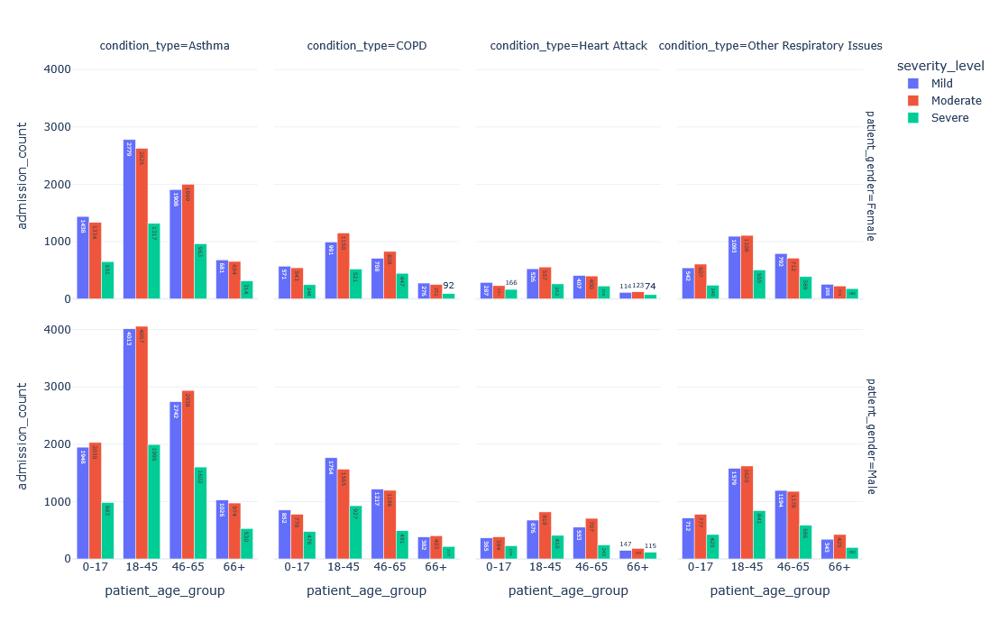

In [71]:
px.bar(severe_df,x='patient_age_group',y='admission_count',color='severity_level',facet_col='condition_type',facet_row='patient_gender',barmode='group',template='plotly_white',height=700,width=1500,text_auto=True)

### Encoding Ordinal categorical columns:

In [30]:
severity_mapping={'Mild':1,'Moderate':2,'Severe':3}
df['Severity_Encoded']=df['severity_level'].map(severity_mapping)
df['Severity_Encoded']

0        2
1        1
2        2
3        1
4        2
        ..
41539    2
41540    1
41541    2
41542    1
41543    1
Name: Severity_Encoded, Length: 41544, dtype: int64

In [31]:
age_mapping={'0-17':1,'18-45':2,'46-65':3,'66+':4}
df['age_Encoded']=df['patient_age_group'].map(age_mapping)
df['age_Encoded']

0        3
1        1
2        3
3        3
4        2
        ..
41539    3
41540    1
41541    3
41542    2
41543    4
Name: age_Encoded, Length: 41544, dtype: int64

In [32]:
gender_mapping={'Male':0,'Female':2}
df['gender_Encoded']=df['patient_gender'].map(gender_mapping)
df['gender_Encoded']

0        2
1        2
2        2
3        0
4        2
        ..
41539    0
41540    0
41541    0
41542    0
41543    2
Name: gender_Encoded, Length: 41544, dtype: int64

In [33]:
condition_encoded = pd.get_dummies(df['condition_type'], prefix='condition', dtype=int)
condition_encoded

,condition_Asthma,condition_COPD,condition_Heart Attack,condition_Other Respiratory Issues
0,1,0,0,0
1,1,0,0,0
2,1,0,0,0
3,1,0,0,0
4,0,1,0,0
...,...,...,...,...
41539,1,0,0,0
41540,0,1,0,0
41541,1,0,0,0
41542,1,0,0,0


In [34]:
df_encoded = pd.concat([df, condition_encoded], axis=1)
df_encoded

,admission_date,hospital_name,admission_count,condition_type,patient_age_group,patient_gender,readmission_count,severity_level,length_of_stay_avg,seasonal_indicator,...,Year,Month,Hour,Severity_Encoded,age_Encoded,gender_Encoded,condition_Asthma,condition_COPD,condition_Heart Attack,condition_Other Respiratory Issues
0,2020-01-01 00:00:00,Mecca City Hospital,1,Asthma,46-65,Female,0,Moderate,2.781828,Winter,...,2020,January,0,2,3,2,1,0,0,0
1,2020-01-01 01:00:00,Dammam General Hospital,2,Asthma,0-17,Female,1,Mild,4.141432,Winter,...,2020,January,1,1,1,2,1,0,0,0
2,2020-01-01 02:00:00,Mecca City Hospital,1,Asthma,46-65,Female,1,Moderate,8.507026,Winter,...,2020,January,2,2,3,2,1,0,0,0
3,2020-01-01 03:00:00,Medina Specialist Hospital,3,Asthma,46-65,Male,0,Mild,4.622657,Winter,...,2020,January,3,1,3,0,1,0,0,0
4,2020-01-01 04:00:00,Medina Specialist Hospital,5,COPD,18-45,Female,2,Moderate,5.818385,Winter,...,2020,January,4,2,2,2,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41539,2024-09-26 19:00:00,King Saud Hospital,4,Asthma,46-65,Male,1,Moderate,6.560851,Fall,...,2024,September,19,2,3,0,1,0,0,0
41540,2024-09-26 20:00:00,Dammam General Hospital,3,COPD,0-17,Male,0,Mild,4.453949,Fall,...,2024,September,20,1,1,0,0,1,0,0
41541,2024-09-26 21:00:00,Riyadh National Hospital,2,Asthma,46-65,Male,0,Moderate,4.248567,Fall,...,2024,September,21,2,3,0,1,0,0,0
41542,2024-09-26 22:00:00,King Saud Hospital,0,Asthma,18-45,Male,0,Mild,4.666558,Fall,...,2024,September,22,1,2,0,1,0,0,0


In [35]:
df_encoded_clos= list(df_encoded.select_dtypes(include='number'))
df_encoded_clos

['admission_count',
 'readmission_count',
 'length_of_stay_avg',
 'comorbid_conditions_count',
 'daily_medication_dosage',
 'emergency_visit_count',
 'Year',
 'Hour',
 'Severity_Encoded',
 'age_Encoded',
 'gender_Encoded',
 'condition_Asthma',
 'condition_COPD',
 'condition_Heart Attack',
 'condition_Other Respiratory Issues']

In [36]:
selected_col=['admission_count',
 'readmission_count',
 'length_of_stay_avg',
 'comorbid_conditions_count',
 'daily_medication_dosage',
 'emergency_visit_count',
 'Severity_Encoded',
 'age_Encoded',
 'gender_Encoded',
 'condition_Asthma',
 'condition_COPD',
 'condition_Heart Attack',
 'condition_Other Respiratory Issues']
selected_col

['admission_count',
 'readmission_count',
 'length_of_stay_avg',
 'comorbid_conditions_count',
 'daily_medication_dosage',
 'emergency_visit_count',
 'Severity_Encoded',
 'age_Encoded',
 'gender_Encoded',
 'condition_Asthma',
 'condition_COPD',
 'condition_Heart Attack',
 'condition_Other Respiratory Issues']

In [37]:
new_corr_matrix=df_encoded[selected_col].corr()
new_corr_matrix

,admission_count,readmission_count,length_of_stay_avg,comorbid_conditions_count,daily_medication_dosage,emergency_visit_count,Severity_Encoded,age_Encoded,gender_Encoded,condition_Asthma,condition_COPD,condition_Heart Attack,condition_Other Respiratory Issues
admission_count,1.000000,-0.003306,-0.004675,0.002552,0.004654,-0.008431,0.006526,-0.010762,0.002878,-0.000781,0.004905,-0.007576,0.001749
readmission_count,-0.003306,1.000000,-0.002775,0.000090,0.001654,0.003861,0.007268,0.001219,0.003259,-0.004928,0.005724,0.001699,-0.000861
length_of_stay_avg,-0.004675,-0.002775,1.000000,-0.001507,-0.006281,0.002454,-0.002273,0.003177,-0.006813,0.000397,0.000189,0.000703,-0.001218
comorbid_conditions_count,0.002552,0.000090,-0.001507,1.000000,-0.000306,0.000016,0.003648,-0.003420,0.000022,0.005670,-0.002973,-0.005753,0.000216
daily_medication_dosage,0.004654,0.001654,-0.006281,-0.000306,1.000000,0.000155,0.003789,0.003280,0.003442,0.000614,0.000016,0.013265,-0.010780
emergency_visit_count,-0.008431,0.003861,0.002454,0.000016,0.000155,1.000000,-0.000578,-0.001072,0.008821,-0.006461,0.005144,0.003207,0.000508
Severity_Encoded,0.006526,0.007268,-0.002273,0.003648,0.003789,-0.000578,1.000000,0.007630,-0.004925,-0.002437,-0.004200,0.003452,0.004683
age_Encoded,-0.010762,0.001219,0.003177,-0.003420,0.003280,-0.001072,0.007630,1.000000,-0.003765,0.000692,-0.003214,0.004685,-0.001162
gender_Encoded,0.002878,0.003259,-0.006813,0.000022,0.003442,0.008821,-0.004925,-0.003765,1.000000,-0.001966,-0.008161,0.010365,0.002871
condition_Asthma,-0.000781,-0.004928,0.000397,0.005670,0.000614,-0.006461,-0.002437,0.000692,-0.001966,1.000000,-0.502380,-0.333573,-0.496932


In [38]:
new_fig_corr=px.imshow(new_corr_matrix,text_auto='.4f',color_continuous_scale='darkmint',aspect='auto',width=1000,height=850)
new_fig_corr.update_layout(margin=dict(l=150))
new_fig_corr

In [72]:
readmission_summary = (df.groupby(['hospital_name', 'condition_type']).agg({'readmission_count': 'sum','emergency_visit_count': 'sum','admission_count': 'sum',}).reset_index())
readmission_summary

,hospital_name,condition_type,readmission_count,emergency_visit_count,admission_count
0,Dammam Central Hospital,Asthma,1295,2585,5254
1,Dammam Central Hospital,COPD,495,1036,1987
2,Dammam Central Hospital,Heart Attack,258,550,1040
3,Dammam Central Hospital,Other Respiratory Issues,495,1145,2214
4,Dammam General Hospital,Asthma,1283,2654,5150
5,Dammam General Hospital,COPD,540,1091,2106
6,Dammam General Hospital,Heart Attack,233,467,966
7,Dammam General Hospital,Other Respiratory Issues,475,960,1955
8,Jeddah National Hospital,Asthma,1316,2535,5224
9,Jeddah National Hospital,COPD,544,1064,2192


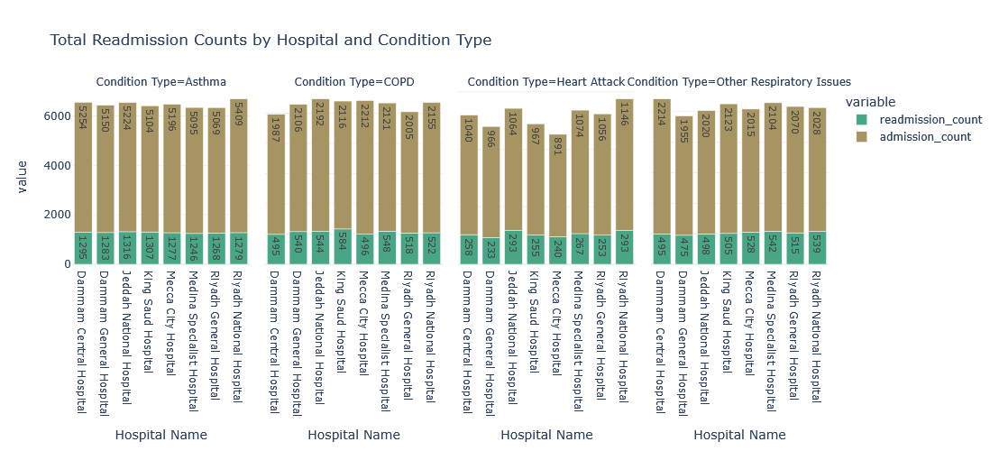

In [109]:
fig_readmit = px.bar(readmission_summary,x='hospital_name',y=['readmission_count','admission_count'],facet_col='condition_type',template='plotly_white',text_auto=True , title='Total Readmission Counts by Hospital and Condition Type',color_discrete_sequence=['#49A684','#A69563'],labels={'readmission_count': 'Total Readmissions','hospital_name': 'Hospital Name','condition_type': 'Condition Type'},width=1500,height=500)
fig_readmit.update_xaxes(matches=None,showticklabels=True)
fig_readmit.update_yaxes(matches=None)
fig_readmit

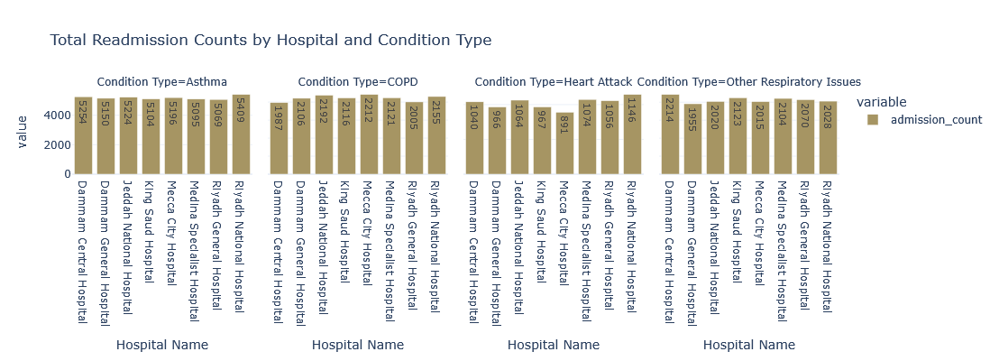

In [111]:
fig_ad_con = px.bar(readmission_summary,x='hospital_name',y=['admission_count'],facet_col='condition_type',template='plotly_white',text_auto=True , title='Total Readmission Counts by Hospital and Condition Type',color_discrete_sequence=['#A69563'],labels={'readmission_count': 'Total Readmissions','hospital_name': 'Hospital Name','condition_type': 'Condition Type'},width=1500,height=400)
fig_ad_con.update_xaxes(matches=None,showticklabels=True)
fig_ad_con.update_yaxes(matches=None)
fig_ad_con

In [132]:
import os
os.getcwd()

'C:\\Users\\Latif'

In [136]:
os.chdir(r"C:\Users\Latif\Desktop\Epsilon Data Analysis With Python Project")

In [137]:
df.to_csv('Cleaned Riyadh Cardiorespiratory Hospital Admissions.csv')

In [141]:
! pip install streamlit pandas plotly

In [162]:
%%writefile app.py
import streamlit as st
import numpy as np
import pandas as pd
import plotly.express as px

st.set_page_config(page_title='Riyadh Cardiorespiratory Hospital Admissions Dashboard', page_icon="🏥", layout="wide")

# Load data with caching and date parsing
@st.cache_data
def load_data():
    df = pd.read_csv(r"C:\Users\Latif\Desktop\Epsilon Data Analysis With Python Project\Cleaned Riyadh Cardiorespiratory Hospital Admissions.csv")
    df['admission_date'] = pd.to_datetime(df['admission_date'])
    df['year'] = df['admission_date'].dt.year
    df['month'] = df['admission_date'].dt.month
    return df

df = load_data()

st.title('🏥 Riyadh Cardiorespiratory Hospital Admissions Dashboard')
st.markdown("Comprehensive analysis dashboard covering admissions, severity, length of stay, and patient demographics (2022–2024).")

# --- Sidebar Filters ---
st.sidebar.header("🎛️ Filter Options")

# 1. Date Range Filter
min_date = df['admission_date'].min().date()
max_date = df['admission_date'].max().date()

selected_dates = st.sidebar.date_input(
    "Select Date Range:",
    value=(min_date, max_date),
    min_value=min_date,
    max_value=max_date
)

# 2. Hospital Filter
hospitals = sorted(df['hospital_name'].unique())
selected_hospitals = st.sidebar.multiselect("Select Hospitals:", options=hospitals, default=hospitals)

# 3. Condition Type Filter
conditions = sorted(df['condition_type'].unique())
selected_conditions = st.sidebar.multiselect("Select Condition Types:", options=conditions, default=conditions)

# Handle date selection safely using type()
if type(selected_dates) == tuple and len(selected_dates) == 2:
    start_date, end_date = selected_dates
else:
    start_date, end_date = min_date, max_date

# Filter dataframe based on selections
filtered_df = df[
    (df['admission_date'].dt.date >= start_date) &
    (df['admission_date'].dt.date <= end_date) &
    (df['hospital_name'].isin(selected_hospitals)) & 
    (df['condition_type'].isin(selected_conditions))
]

# --- KPIs Metrics ---
st.markdown("---")
col1, col2, col3 = st.columns(3)

total_admissions = len(filtered_df)
avg_los = round(filtered_df['length_of_stay'].mean(), 2) if 'length_of_stay' in filtered_df.columns else 0
total_emergency = int(filtered_df['emergency_visits'].sum()) if 'emergency_visits' in filtered_df.columns else 0

col1.metric(label="📊 Total Admissions", value=f"{total_admissions:,}")
col2.metric(label="⏱️ Average Length of Stay", value=f"{avg_los} Days")
col3.metric(label="🚨 Emergency Visits", value=f"{total_emergency:,}")

st.markdown("---")

# --- Tabs for the 6 Analysis Charts ---
tab1, tab2, tab3, tab4, tab5, tab6 = st.tabs([
    "📈 1. Seasonal Trends", 
    "🩺 2. Condition Severity", 
    "🏥 3. Length of Stay", 
    "🚨 4. Emergency Visits", 
    "👥 5. Patient Demographics", 
    "📊 6. Hospital Comparison"
])

# Chart 1: Seasonal & Monthly Trends
with tab1:
    st.subheader("Chart 1: Monthly Admissions Trends Over Years")
    if not filtered_df.empty:
        monthly_admissions = filtered_df.groupby(['year', 'month']).size().reset_index(name='admission_count')
        fig1 = px.line(
            monthly_admissions, x='month', y='admission_count', color=monthly_admissions['year'].astype(str),
            markers=True, title='Monthly Admissions Trend Comparison',
            labels={'month': 'Month', 'admission_count': 'Admission Count', 'color': 'Year'}
        )
        fig1.update_layout(xaxis=dict(tickmode='linear', dtick=1))
        st.plotly_chart(fig1, use_container_width=True)
    else:
        st.warning("No data available for the selected filters.")

# Chart 2: Condition Types by Severity Level
with tab2:
    st.subheader("Chart 2: Condition Types and Severity Levels")
    if not filtered_df.empty:
        fig2 = px.histogram(
            filtered_df, x='condition_type', color='severity_level', barmode='group',
            title='Distribution of Severity Levels Across Conditions',
            labels={'condition_type': 'Condition Type', 'count': 'Case Count', 'severity_level': 'Severity Level'}
        )
        st.plotly_chart(fig2, use_container_width=True)
    else:
        st.warning("No data available for the selected filters.")

# Chart 3: Length of Stay by Hospital & Age Group
with tab3:
    st.subheader("Chart 3: Average Length of Stay by Hospital and Age Group")
    if not filtered_df.empty and 'age_group' in filtered_df.columns:
        avg_los_df = filtered_df.groupby(['hospital_name', 'age_group'])['length_of_stay'].mean().reset_index()
        fig3 = px.bar(
            avg_los_df, x='hospital_name', y='length_of_stay', color='age_group', barmode='group',
            title='Average Length of Stay (Days) per Hospital by Age Group',
            labels={'hospital_name': 'Hospital Name', 'length_of_stay': 'Avg Length of Stay (Days)', 'age_group': 'Age Group'}
        )
        st.plotly_chart(fig3, use_container_width=True)
    else:
        st.warning("No data available for the selected filters.")

# Chart 4: Emergency Visits Distribution
with tab4:
    st.subheader("Chart 4: Emergency Visits by Hospital")
    if not filtered_df.empty and 'emergency_visits' in filtered_df.columns:
        emergency_df = filtered_df.groupby('hospital_name')['emergency_visits'].sum().reset_index()
        fig4 = px.bar(
            emergency_df, x='hospital_name', y='emergency_visits', color='hospital_name',
            title='Total Emergency Visits per Hospital',
            labels={'hospital_name': 'Hospital Name', 'emergency_visits': 'Total Emergency Visits'}
        )
        st.plotly_chart(fig4, use_container_width=True)
    else:
        st.warning("No data available for the selected filters.")

# Chart 5: Patient Demographics (Gender Distribution)
with tab5:
    st.subheader("Chart 5: Patient Gender Distribution across Conditions")
    if not filtered_df.empty and 'patient_gender' in filtered_df.columns:
        gender_df = filtered_df.groupby(['condition_type', 'patient_gender']).size().reset_index(name='count')
        fig5 = px.bar(
            gender_df, x='condition_type', y='count', color='patient_gender', barmode='group',
            title='Patient Gender Breakdown per Condition Type',
            labels={'condition_type': 'Condition Type', 'count': 'Patient Count', 'patient_gender': 'Gender'}
        )
        st.plotly_chart(fig5, use_container_width=True)
    else:
        st.warning("No data available for the selected filters.")

# Chart 6: Total Admissions Volume per Hospital
with tab6:
    st.subheader("Chart 6: Total Admissions Volume per Hospital")
    if not filtered_df.empty:
        hospital_vol = filtered_df.groupby('hospital_name').size().reset_index(name='total_admissions')
        fig6 = px.bar(
            hospital_vol, x='hospital_name', y='total_admissions', color='hospital_name',
            title='Total Hospital Admissions Volume',
            labels={'hospital_name': 'Hospital Name', 'total_admissions': 'Total Admissions'}
        )
        st.plotly_chart(fig6, use_container_width=True)
    else:
        st.warning("No data available for the selected filters.")

Overwriting app.py
